<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/models/Copy_of_Copy_KL_FuseNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip install --upgrade --force-reinstall sympy

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.0


In [4]:
import sympy
import torch
import timm

print("SymPy:", sympy.__version__)
print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("CUDA available:", torch.cuda.is_available())

SymPy: 1.14.0
PyTorch: 2.11.0+cu130
timm: 1.0.30
CUDA available: True


## 1. Dataset

**What this cell does:** downloads the knee X-ray dataset and prints a few file
names to confirm the patient IDs are intact.

**What the paper did:** used 8,260 knee radiographs from 4,130 patients, taken
from a public Mendeley release organised from the Osteoarthritis Initiative
(OAI). File names follow the pattern `{patient_ID}{L|R}`, for example
`9001400L` and `9001400R` are the left and right knee of patient 9001400
(Section 2.1).

**How we applied it:** we download the Kaggle mirror of that same Mendeley
dataset, because it keeps the original file names. The printed sample proves the
patient IDs survived, which is exactly what the patient-wise split in step 5
needs.

In [1]:
import kagglehub, os
from pathlib import Path

root = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")

names = [p.stem for p in Path(root).rglob("*") if p.suffix.lower() in [".png", ".jpg", ".jpeg"]]
print("total images:", len(names))
print("sample names:", names[:10])

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
total images: 9786
sample names: ['9095865R', '9845238R', '9060930L', '9155763L', '9861824L', '9288025R', '9889523R', '9724907R', '9991313R', '9959748R']


## 2. Where results are saved

**What this cell does:** mounts Google Drive and creates one folder for all
outputs of this run.

**What the paper did:** not discussed; the paper does not describe its file
handling.

**How we applied it:** this is our own addition. Everything we produce (the
split table, the model weights, the checkpoints) is written to Drive, so a
dropped Colab session never costs us any work. Each experiment gets its own
folder name, so runs never overwrite each other.

In [2]:
# --- Mount Drive and set the working directory ---
# WORK_DIR is where everything we produce is saved: tables, splits, checkpoints.

from google.colab import drive
drive.mount("/content/drive")

WORK_DIR = "/content/drive/MyDrive/MUFSAL/run1"
os.makedirs(WORK_DIR, exist_ok=True)
print("Work directory:", WORK_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Work directory: /content/drive/MyDrive/MUFSAL/run1


## 3. Library install

**What this cell does:** installs `timm`.

**What the paper did:** used `timm` version 1.0.20 to load the pretrained
backbones, ConvNeXt-Base and ResNet-50 (Section 2.9).

**How we applied it:** same library. We install the current version rather than
pinning 1.0.20; the two model weights we need are published under the same names,
so the loaded weights are identical.

In [3]:
!pip install -q timm

## 4. Imports and reproducibility

**What this cell does:** imports the libraries and fixes every random seed, so
re-running the notebook gives the same numbers.

**What the paper did:** set seed = 42 across Python, NumPy and PyTorch, and
enabled cuDNN determinism (Section 2.9).

**How we applied it:** the same four lines. We also set
`PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True` before importing torch, which
reduces GPU memory fragmentation; this is ours, not in the paper, and it does not
change any result.

In [4]:
import os
import re
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
import timm


# Reproducibility (paper, Section 2.9: seed = 42, cuDNN determinism enabled)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Torch:", torch.__version__, "| timm:", timm.__version__)

Device: cuda
Torch: 2.11.0+cu130 | timm: 1.0.30


## 5. Building the image table

**What this cell does:** walks through the dataset folders and builds one table
with a row per image: its path, its KL grade, its patient ID and which knee it
is. The KL grade is taken from the name of the folder the image sits in.

**What the paper did:** worked with the 8,260 images in train + val + test, and
recovered each patient's ID by removing the trailing L/R from the file name, so
that the two knees of one patient can be kept together later (Section 2.1).

**How we applied it:** the same. We skip the `auto_test` folder, which holds a
further 1,526 images and is not part of the 8,260 the paper used. Our totals
match the paper exactly: 8,260 images, 4,130 patients, and a grade distribution
of 3253 / 1495 / 2175 / 1086 / 251, which is Table 1 of the paper. That match is
how we know we are working on the same data they were.

In [5]:
# Build a table with one row per image.
# File names look like "9001400L" = patient 9001400, left knee.
# auto_test is skipped: the paper uses the 8260 images in train + val + test.

rows = []
for split in ["train", "val", "test"]:
    for grade in ["0", "1", "2", "3", "4"]:
        for path in Path(root).glob(f"**/{split}/{grade}/*.png"):
            rows.append({
                "path": str(path),
                "kl": int(grade),
                "orig_split": split,
                "patient_id": path.stem[:-1],      # drop the last letter (L or R)
                "side": path.stem[-1].upper(),
            })

df = pd.DataFrame(rows)

print("images:  ", len(df), "  (paper: 8260)")
print("patients:", df["patient_id"].nunique(), "  (paper: 4130)")
print("names not ending in L/R:", int((~df["side"].isin(["L", "R"])).sum()))

print("\nKL grades:")
print(df["kl"].value_counts().sort_index().to_string())

print("\nsplit sizes:")
print(df["orig_split"].value_counts().to_string())

df.head()

images:   8260   (paper: 8260)
patients: 4130   (paper: 4130)
names not ending in L/R: 0

KL grades:
kl
0    3253
1    1495
2    2175
3    1086
4     251

split sizes:
orig_split
train    5778
test     1656
val       826


,path,kl,orig_split,patient_id,side
0,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9641381,R
1,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9865771,R
2,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9133694,L
3,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9112976,L
4,/kaggle/input/knee-osteoarthritis-dataset-with...,0,train,9381081,L


## 6. Patient-wise split

**What this cell does:** splits the data into training, validation and test
sets, and saves the result to `splits.csv` so every teammate uses the exact same
split.

**What the paper did:** this is the methodological core of the paper. Each
patient contributes two images (left and right knee), and those two knees look
very alike: same bone density, same machine, often the same disease stage. If one
knee lands in training and the other in testing, the model can recognise the
patient instead of the disease, and the reported score comes out too high. The
paper therefore splits by PATIENT, not by image: it labels each patient by their
highest KL grade across both knees, splits the patients 70 / 15 / 15 with
stratification and seed 42, and sends every image of a patient to the same
partition (Section 2.1).

**How we applied it:** the same four steps. `train_test_split` is called twice:
once to take 30% aside, then once to cut that 30% in half. `stratify` keeps the
grade mix roughly equal across the three parts. Our patient counts match the
paper exactly: 2,891 train, 620 validation, 619 test.

In [6]:
from sklearn.model_selection import train_test_split

# Label each patient by their worst knee (paper: highest KL grade across both knees).
patients = df.groupby("patient_id")["kl"].max()

# Split the PATIENTS 70 / 15 / 15, keeping the grade mix equal in each part (seed 42).
train_ids, rest_ids = train_test_split(
    patients.index, test_size=0.30, stratify=patients, random_state=42)
val_ids, test_ids = train_test_split(
    rest_ids, test_size=0.50, stratify=patients[rest_ids], random_state=42)

# Both knees of a patient always land in the same split.
df["split"] = "train"
df.loc[df["patient_id"].isin(val_ids), "split"] = "val"
df.loc[df["patient_id"].isin(test_ids), "split"] = "test"

print(df.groupby("split")["patient_id"].agg(images="size", patients="nunique"))
print()
print(pd.crosstab(df["split"], df["kl"]))

df.to_csv(os.path.join(WORK_DIR, "splits.csv"), index=False)
print("\nsaved splits.csv")

       images  patients
split                  
test     1240       620
train    5782      2891
val      1238       619

kl        0     1     2    3    4
split                            
test    476   227   328  171   38
train  2293  1048  1509  756  176
val     484   220   338  159   37

saved splits.csv


## 7. Loading images and data augmentation


**Does:** turns an image into a tensor and builds the three data loaders.

**Paper (2.2):** resize to 224 x 224, normalise with ImageNet statistics, and
during training only apply four random transforms: horizontal flip p = 0.5,
rotation +-8 degrees, resized crop keeping 88-100%, brightness/contrast jitter
0.08. Validation and test get a plain resize, no randomness. The image is cut at
the midline into two halves, and the whole image and both halves pass through
the same transform stack.

**Us:** same four transforms, same parameters. The dataset returns only the FULL
image and the model cuts it in half (next cell), so both halves automatically
share the same rotation and crop. X-rays are grayscale, so we copy each one into
three channels because ImageNet normalisation expects three.

**One deviation:** the paper used batch 32; our 15 GB GPU ran out of memory, so
we use batch 16 and accumulate over two batches. Effective batch is still 32.

In [7]:
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

BATCH_SIZE = 16   # # paper used 32; we use 16 with 2-step gradient accumulation (15 GB GPU)

# Training: augment (paper, Section 2.2). Val/test: no randomness.
train_tf = T.Compose([
    T.RandomHorizontalFlip(0.5),
    T.RandomRotation(8),
    T.RandomResizedCrop(224, scale=(0.88, 1.0), ratio=(0.9, 1.1)),
    T.ColorJitter(brightness=0.08, contrast=0.08),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


# One image + its KL grade. The model splits the image into halves later.
class KneeData(Dataset):
    def __init__(self, split, tf):
        rows = df[df["split"] == split]
        self.paths = rows["path"].tolist()
        self.labels = rows["kl"].tolist()
        self.tf = tf

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # grayscale -> 3 channels
        return self.tf(img), self.labels[i]


train_loader = DataLoader(KneeData("train", train_tf), BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(KneeData("val",   eval_tf),  BATCH_SIZE, num_workers=2)
test_loader  = DataLoader(KneeData("test",  eval_tf),  BATCH_SIZE, num_workers=2)

print("images ->", len(train_loader.dataset), len(val_loader.dataset), len(test_loader.dataset))
x, y = next(iter(train_loader))
print("batch:", tuple(x.shape), tuple(y.shape))

images -> 5782 1238 1240
batch: (16, 3, 224, 224) (16,)


## 8. The KL-FuseNet model

**Does:** builds the network: three input streams, three output heads.
111.1 million parameters.

**Paper (2.3):** reading a knee X-ray needs two kinds of looking at once, the
overall joint alignment and the local detail at the joint margins. So the whole
image goes to a ConvNeXt-Base, and each half of the image goes to a ResNet-50 --
one network with shared weights, not two. The three feature vectors are pooled
with GeM (pooling whose exponent p is learned, starting at 3.0, so strong regions
count for more than plain averaging), concatenated, passed through dropout 0.1,
L2-normalised, then sent to the three heads.

**Us:** we stack both halves into one batch and run a single forward pass, then
split the result with `chunk(2)` -- this guarantees the weights really are
shared. The midline split is one line. One GeM instance serves both streams,
since its only parameter is a single number.

**`clamp` is ours, not in the paper:** GeM raises its input to the power 3, and
ConvNeXt outputs negative values, which would give NaN. We clip at a tiny
positive floor first. Worth stating in the methodology.

In [8]:
import torch.nn as nn
import torch.nn.functional as F


# GeM pooling (paper, Section 2.3): like average pooling, but the learnable
# exponent p lets the model emphasise the strongest regions. p starts at 3.
# clamp() is ours, not in the paper: ConvNeXt features can be negative and
# raising a negative number to a fractional power gives NaN.
class GeM(nn.Module):
    def __init__(self, p=3.0):
        super().__init__()
        self.p = nn.Parameter(torch.tensor([p]))

    def forward(self, x):
        x = x.float().clamp(min=1e-6).pow(self.p)
        return F.avg_pool2d(x, x.shape[-2:]).pow(1 / self.p).flatten(1)


class KLFuseNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Global stream: the whole image. Patch stream: shared weights, one half at a time.
        self.global_net = timm.create_model("convnext_base.fb_in22k_ft_in1k",
                                            pretrained=True, num_classes=0, global_pool="")
        self.patch_net = timm.create_model("resnet50.a1_in1k",
                                           pretrained=True, num_classes=0, global_pool="")
        self.pool = GeM()
        self.dropout = nn.Dropout(0.1)

        n = self.global_net.num_features + 2 * self.patch_net.num_features   # 1024 + 2x2048
        self.head_ordinal = nn.Linear(n, 4)   # is the grade above 0, 1, 2, 3 ?
        self.head_dist = nn.Linear(n, 5)      # probability of each grade 0..4
        self.head_binary = nn.Linear(n, 1)    # KL >= 2 or not

    def forward(self, x):
        half = x.shape[-1] // 2
        left, right = x[..., :half], x[..., half:]

        f_global = self.pool(self.global_net.forward_features(x))
        f_both = self.pool(self.patch_net.forward_features(torch.cat([left, right])))
        f_left, f_right = f_both.chunk(2)

        f = torch.cat([f_global, f_left, f_right], dim=1)
        f = F.normalize(self.dropout(f), dim=1)
        return self.head_ordinal(f), self.head_dist(f), self.head_binary(f).squeeze(1)


model = KLFuseNet().to(DEVICE)

# no_grad: this is only a shape check, so do not keep the gradient graph in memory.
with torch.no_grad():
    x, y = next(iter(val_loader))
    ordinal, dist, binary = model(x.to(DEVICE))

print("ordinal:", tuple(ordinal.shape), "| dist:", tuple(dist.shape),
      "| binary:", tuple(binary.shape))
print("parameters:", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "M")
print(f"GPU used: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

ordinal: (16, 4) | dist: (16, 5) | binary: (16,)
parameters: 111.1 M
GPU used: 0.45 GB


## 9. The three targets and the loss

**Does:** turns each true grade into three targets, and sums the three losses.

**Paper (2.4):** the ordinal head learns "is the grade above 0, 1, 2, 3?"; the
distribution head learns a bell curve centred on the true grade (sigma 1)
instead of a single 1, so predicting a neighbouring grade is punished less than
a far one; the binary head learns KL >= 2. All three losses carry weight 1.0.

**Us:** same, written as three lookup tables of five rows, so `ORDINAL[y]` just
picks the row for each label. The paper applies no class weighting or balanced
sampling, and neither do we.

In [9]:
# ---- The three targets, one row per grade (paper, Section 2.4) ----

# Ordinal: "is the grade above 0, 1, 2, 3 ?"
ORDINAL = torch.tensor([
    [0., 0., 0., 0.],   # grade 0
    [1., 0., 0., 0.],   # grade 1
    [1., 1., 0., 0.],   # grade 2
    [1., 1., 1., 0.],   # grade 3
    [1., 1., 1., 1.],   # grade 4
]).to(DEVICE)

# Binary: clinically significant osteoarthritis starts at grade 2.
BINARY = torch.tensor([0., 0., 1., 1., 1.]).to(DEVICE)

# Distribution: a bell curve centred on the true grade (sigma = 1) instead of a
# single 1, so predicting a neighbouring grade is punished less than a far one.
grades = torch.arange(5).float()
DIST = torch.exp(-0.5 * (grades[None] - grades[:, None]) ** 2)
DIST = (DIST / DIST.sum(1, keepdim=True)).to(DEVICE)

print("distribution targets, one row per grade:")
print(DIST.round(decimals=2))


def compute_loss(ordinal, dist, binary, y):
    """Sum of the three losses, all with weight 1.0 (paper, Section 2.4)."""
    loss_ordinal = F.binary_cross_entropy_with_logits(ordinal.float(), ORDINAL[y])
    loss_dist = F.kl_div(F.log_softmax(dist.float(), dim=1), DIST[y], reduction="batchmean")
    loss_binary = F.binary_cross_entropy_with_logits(binary.float(), BINARY[y])
    return loss_ordinal + loss_dist + loss_binary

distribution targets, one row per grade:
tensor([[0.5700, 0.3500, 0.0800, 0.0100, 0.0000],
        [0.2600, 0.4200, 0.2600, 0.0600, 0.0000],
        [0.0500, 0.2400, 0.4000, 0.2400, 0.0500],
        [0.0000, 0.0600, 0.2600, 0.4200, 0.2600],
        [0.0000, 0.0100, 0.0800, 0.3500, 0.5700]], device='cuda:0')


## 10. Optimizer, schedule, EMA

**Does:** sets up training and defines the validation score.

**Paper (2.4):** AdamW, backbones at 1e-4 and heads at twice that, weight decay
1e-4, cosine schedule with a 3-epoch warm-up, mixed precision, and an EMA copy
of the weights (decay 0.999) scored alongside the live weights. Model selection
and early stopping both use validation QWK, patience 12, max 60 epochs.

**Us:** same values. We separate head from backbone parameters by their name,
and use `timm`'s ready-made `ModelEmaV3` instead of writing EMA ourselves.
QWK is the only metric here, as in the paper; accuracy and F1 come later, on the
test set.

In [10]:
from timm.utils import ModelEmaV3
from sklearn.metrics import cohen_kappa_score

EPOCHS = 60       # paper: maximum 60
PATIENCE = 12     # paper: early stopping on validation QWK

# Two learning rates: backbones at 1e-4, the heads and the pooling at twice that
# (paper, Section 2.4). We tell them apart by the name we gave them in the model.
head_params, backbone_params = [], []
for name, p in model.named_parameters():
    if name.startswith(("head", "pool")):
        head_params.append(p)
    else:
        backbone_params.append(p)

optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": 1e-4},
    {"params": head_params, "lr": 2e-4},
], weight_decay=1e-4)

# Learning rate rises for 3 epochs, then follows a cosine curve down (paper).
warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=3)
cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS - 3)
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[3])

scaler = torch.amp.GradScaler("cuda")      # mixed precision
ema = ModelEmaV3(model, decay=0.999)       # a slowly averaged copy of the weights


@torch.no_grad()
def validate(net):
    """Score the validation set with quadratic-weighted kappa (QWK)."""
    net.eval()
    true, pred = [], []
    for x, y in val_loader:
        ordinal, _, _ = net(x.to(DEVICE))
        # The grade is how many of the four "is it above k?" answers came out yes.
        pred += (torch.sigmoid(ordinal) > 0.5).sum(1).cpu().tolist()
        true += y.tolist()
    return cohen_kappa_score(true, pred, weights="quadratic")


print("head tensors:", len(head_params), "| backbone tensors:", len(backbone_params))

head tensors: 7 | backbone tensors: 501


## 11. Checkpoints

**Does:** saves training state, and resumes automatically if the session was
dropped.

**Paper:** not discussed.

**Us:** entirely ours. `best.pt` holds the weights of the best validation epoch;
`checkpoint.pt` holds the full state every 5 epochs. Re-running the training
cell after a disconnect continues from the last checkpoint instead of starting
over.

In [11]:
CKPT = os.path.join(WORK_DIR, "checkpoint.pt")
BEST = os.path.join(WORK_DIR, "best.pt")

start_epoch, best_qwk, stale = 1, -1.0, 0

# If an earlier Colab session was dropped, continue from its checkpoint.
if os.path.exists(CKPT):
    ck = torch.load(CKPT, weights_only=False)
    model.load_state_dict(ck["model"])
    ema.module.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])
    start_epoch, best_qwk, stale = ck["epoch"] + 1, ck["best_qwk"], ck["stale"]
    print(f"resuming at epoch {start_epoch}, best QWK {best_qwk:.4f}")
else:
    print("starting from scratch")


def save_checkpoint(epoch):
    torch.save({"model": model.state_dict(), "ema": ema.module.state_dict(),
                "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "epoch": epoch,
                "best_qwk": best_qwk, "stale": stale}, CKPT)

starting from scratch


## 12. Training loop

**Does:** trains, scores both weight copies on validation each epoch, keeps the
better one, and stops when nothing improves.

**Paper (2.4):** early stopping on validation QWK with patience 12; both the raw
and the EMA weights are checkpointed whenever they improve.

**Us:** same, plus gradient accumulation over two batches (see cell 7) so the
effective batch matches the paper's 32. `best.pt` is frozen at the best
validation epoch, so later epochs that overfit are never kept.

In [12]:
ACCUM = 2   # 16 x 2 = effective batch of 32, same as the paper

for epoch in range(start_epoch, EPOCHS + 1):

    # ---- one pass over the training set ----
    model.train()
    total_loss = 0.0
    optimizer.zero_grad()

    for step, (x, y) in enumerate(train_loader, start=1):
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            ordinal, dist, binary = model(x)
        loss = compute_loss(ordinal, dist, binary, y)

        # Divide by ACCUM so two half-batches add up to one normal step.
        scaler.scale(loss / ACCUM).backward()
        total_loss += loss.item()

        if step % ACCUM == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            ema.update(model)

    scheduler.step()

    # ---- score on validation, keep the better of the two weight copies ----
    qwk_raw = validate(model)
    qwk_ema = validate(ema.module)

    if max(qwk_raw, qwk_ema) > best_qwk:
        best_qwk = max(qwk_raw, qwk_ema)
        stale = 0
        torch.save((ema.module if qwk_ema > qwk_raw else model).state_dict(), BEST)
    else:
        stale += 1

    print(f"epoch {epoch:2d} | loss {total_loss / len(train_loader):.4f} | "
          f"QWK raw {qwk_raw:.4f} ema {qwk_ema:.4f} | best {best_qwk:.4f} | stale {stale}")

    if epoch % 5 == 0:
        save_checkpoint(epoch)

    if stale >= PATIENCE:
        print("early stopping")
        break

epoch  1 | loss 1.7815 | QWK raw 0.3023 ema 0.0150 | best 0.3023 | stale 0
epoch  2 | loss 1.4982 | QWK raw 0.6357 ema 0.0284 | best 0.6357 | stale 0
epoch  3 | loss 1.1262 | QWK raw 0.6711 ema 0.2933 | best 0.6711 | stale 0
epoch  4 | loss 0.9216 | QWK raw 0.6727 ema 0.4234 | best 0.6727 | stale 0
epoch  5 | loss 0.7945 | QWK raw 0.7832 ema 0.6479 | best 0.7832 | stale 0
epoch  6 | loss 0.7209 | QWK raw 0.7938 ema 0.6820 | best 0.7938 | stale 0
epoch  7 | loss 0.6490 | QWK raw 0.7961 ema 0.6999 | best 0.7961 | stale 0
epoch  8 | loss 0.6265 | QWK raw 0.7915 ema 0.7486 | best 0.7961 | stale 1
epoch  9 | loss 0.5712 | QWK raw 0.7978 ema 0.7737 | best 0.7978 | stale 0
epoch 10 | loss 0.5276 | QWK raw 0.7961 ema 0.7802 | best 0.7978 | stale 1
epoch 11 | loss 0.4918 | QWK raw 0.7999 ema 0.7859 | best 0.7999 | stale 0
epoch 12 | loss 0.4543 | QWK raw 0.7996 ema 0.7910 | best 0.7999 | stale 1
epoch 13 | loss 0.4183 | QWK raw 0.8050 ema 0.7997 | best 0.8050 | stale 0
epoch 14 | loss 0.3860 | 

## 13. Test the best model
**What this does:** loads the weights from the best validation epoch and evaluates them once on the held-out test set.

Important: use the test set only for final evaluation. Do not use its results to choose settings or train the model.

In [13]:
from sklearn.metrics import (
    accuracy_score, f1_score, cohen_kappa_score,
    classification_report, confusion_matrix
)

# Load the best checkpoint selected using validation QWK.
if not os.path.exists(BEST):
    raise FileNotFoundError(
        f"Could not find {BEST}. Run the training cell first."
    )

model.load_state_dict(torch.load(BEST, map_location=DEVICE, weights_only=True))
model.eval()

y_true, y_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)

        # Mixed precision is used only when running on a GPU.
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda")
        ):
            ordinal_logits, _, _ = model(x)

        # Four yes/no answers: count how many thresholds are passed.
        predictions = (torch.sigmoid(ordinal_logits.float()) > 0.5).sum(dim=1)

        y_true.extend(y.tolist())
        y_pred.extend(predictions.cpu().tolist())

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test macro F1:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Test QWK:", round(cohen_kappa_score(y_true, y_pred, weights="quadratic"), 4))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=[0, 1, 2, 3, 4],
    target_names=["KL 0", "KL 1", "KL 2", "KL 3", "KL 4"],
    zero_division=0
))
print("Confusion matrix (rows = true grade, columns = predicted grade):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))


Test accuracy: 0.6879
Test macro F1: 0.691
Test QWK: 0.8534

Classification report:
              precision    recall  f1-score   support

        KL 0       0.74      0.85      0.79       476
        KL 1       0.35      0.35      0.35       227
        KL 2       0.76      0.63      0.69       328
        KL 3       0.79      0.80      0.79       171
        KL 4       1.00      0.71      0.83        38

    accuracy                           0.69      1240
   macro avg       0.73      0.67      0.69      1240
weighted avg       0.69      0.69      0.69      1240

Confusion matrix (rows = true grade, columns = predicted grade):
[[404  67   4   1   0]
 [112  79  34   2   0]
 [ 26  73 206  23   0]
 [  1   5  28 137   0]
 [  0   0   0  11  27]]


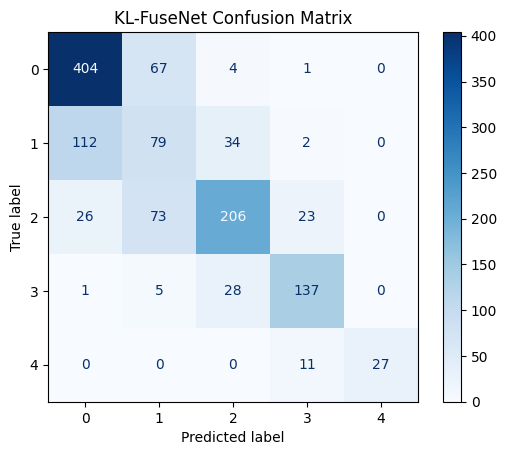

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4])

ConfusionMatrixDisplay(cm, display_labels=[0, 1, 2, 3, 4]).plot(cmap="Blues")
plt.title("KL-FuseNet Confusion Matrix")
plt.show()

## 14. Test-time augmentation (TTA)
TTA makes several slightly changed versions of each test image, predicts each version, then averages the predictions. This can make predictions less sensitive to small image changes.

The paper describes eight views: the original image, a horizontal flip, and small rotations. Run this cell only after the basic test evaluation works. It takes longer.

In [14]:
import torchvision.transforms.functional as TF
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Eight views: original, flipped, and rotations of +/-3, +/-5, +/-7 degrees.
def make_tta_views(x):
    views = [x, torch.flip(x, dims=[3])]
    for angle in [3, -3, 5, -5, 7, -7]:
        views.append(TF.affine(
            x, angle=angle, translate=[0, 0], scale=1.0,
            shear=[0.0, 0.0]
        ))
    return views

model.eval()
tta_true, tta_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        all_ordinal_probs = []

        for view in make_tta_views(x):
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda")
            ):
                ordinal_logits, _, _ = model(view)

            all_ordinal_probs.append(torch.sigmoid(ordinal_logits.float()))

        # Average the four threshold probabilities across the eight views.
        mean_probs = torch.stack(all_ordinal_probs).mean(dim=0)
        predictions = (mean_probs > 0.5).sum(dim=1)

        tta_true.extend(y.tolist())
        tta_pred.extend(predictions.cpu().tolist())

print("TTA accuracy:", round(accuracy_score(tta_true, tta_pred), 4))
print("TTA macro F1:", round(f1_score(tta_true, tta_pred, average="macro", zero_division=0), 4))
print("TTA QWK:", round(cohen_kappa_score(tta_true, tta_pred, weights="quadratic"), 4))


TTA accuracy: 0.6855
TTA macro F1: 0.6942
TTA QWK: 0.8569
